# Lab 3 — Millions of TVs, Who Is Watching?
Name: Artem Khailo | Group: KM-42

## Setup

In [26]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


## Task 1.1 — Five questions

**Answer:**

| | `acr_sessions` (smart TVs) | Lab 1 `viewings` (panel) |
|---|---|---|
| **Grain** | one viewing session on one smart TV, to the second; it ends when the network, program or input changes | one viewing session of one person (or one household's TV set) on one of the ten networks, to the minute |
| **Key** | `session_id`; the TV is `tv_id` and it links to households only through `hashed_ip` | `viewing_id`; `respondent_id` links to `daily_weights` and `viewer_attributes` |
| **Coverage** | about 30,000 opted-in smart TVs, one TV per home, October 14–27, any US network plus apps and unrecognized viewing | about 4,000 recruited homes, all their people and TV sets, October 1–31, only the ten networks |
| **Weight** | none: every TV counts once | daily weights that project each household and person to the US population |
| **Provenance** | automatic content recognition on the TV, from owners who opted in; sold by a data vendor | a measurement panel recruited and weighted to represent the US |

The biggest difference is the **weight**: the panel was recruited and weighted to stand for all US TV homes, while the smart-TV data is a convenience sample of whoever bought this TV and opted in, with no weights, so its counts cannot be projected to the US as they are.

## Task 1.2 — Size and shape

In [27]:
acr=acr_sessions.copy()
acr["start"]=pd.to_datetime(acr["start_utc"], utc=True).dt.tz_convert("America/New_York").dt.tz_localize(None)
acr["end"]=pd.to_datetime(acr["end_utc"], utc=True).dt.tz_convert("America/New_York").dt.tz_localize(None)
acr["bday"]=(acr["start"] - pd.Timedelta(hours=6)).dt.normalize()
acr["hours"]= (acr["end"] - acr["start"]).dt.total_seconds() / 3600
acr_ok =acr[acr["end"] - acr["start"] >= pd.Timedelta(minutes=1)]
tv_days =acr_ok[["tv_id", "bday"]].drop_duplicates()
n_days =acr["bday"].nunique()

print("TVs:", acr["tv_id"].nunique())
print("Sessions:", len(acr))
print("Broadcast days:", n_days)
print("Average TVs in-tab per day:", round(len(tv_days) / n_days, 1))
print("Hours per TV per day, raw:", f'{acr["hours"].sum() / len(tv_days):.2f}')
print("Hours per TV per day, after edit rule:", f'{acr_ok["hours"].sum() / len(tv_days):.2f}')
print("Share of sessions dropped:", round(1 - len(acr_ok) / len(acr), 3))

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.1
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 0.299


## Task 1.3 — What the TV could not see

In [28]:
by_type= acr_ok.groupby("session_type")["hours"].sum()/ acr_ok["hours"].sum()
by_input=acr_ok.groupby("input_source")["hours"].sum()/ acr_ok["hours"].sum()
print(by_type.sort_values(ascending=False).round(3))
print(by_input.sort_values(ascending=False).round(3))
print("Share of TV-on hours unknown (%):", round(by_type["unknown"] * 100, 1))

session_type
unknown    0.396
live       0.322
app        0.257
dvr        0.025
Name: hours, dtype: float64
input_source
built_in_app        0.307
cable_box           0.276
streaming_device    0.231
antenna             0.086
satellite_box       0.076
game_or_disc        0.024
Name: hours, dtype: float64
Share of TV-on hours unknown (%): 39.6


**Answer:** In this feed 39.6% of TV-on hours are unknown: the TV was on, but the fingerprint did not match any live feed. A real ACR feed can have even more, because a real fingerprint library holds only some live feeds, so smaller channels, many local stations and on-demand or old content find no match, and menus, overlays, picture-in-picture or a weak signal can also break the match. Two kinds of viewing that end up as unknown are streaming through an external device such as a Roku or Fire TV stick (`streaming_device`, 23.1% of hours here) and video games or DVD/Blu-ray discs (`game_or_disc`, 2.4%), because neither is a live TV feed that the library could recognise.

## Task 2.1 — Match

In [29]:
tvs=acr[["tv_id", "hashed_ip"]].drop_duplicates()
hh_per_ip=hh_attributes.groupby("hashed_ip").size()
tvs["n_hh"]= tvs["hashed_ip"].map(hh_per_ip).fillna(0)

print("Matched to one household (%):", round((tvs["n_hh"]== 1).mean() * 100, 1))
print("Shared IP, unresolved (%):", round((tvs["n_hh"]> 1).mean() * 100, 1))
print("Not matched (%):", round((tvs["n_hh"]== 0).mean() * 100, 1))

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:** Only 65.2% of the TVs can be linked to exactly one household; 11.8% sit on an IP address that several households share and 22.9% match nobody. An IP address is a weak key because it does not belong to one home for good: several homes can share one address (an apartment building, a shared Wi-Fi network), internet providers change home addresses from time to time, so the consumer file may hold an old one and the same home can also appear under other addresses (a VPN or a phone). Hashing hides the address but does not fix any of this, so about a third of the TVs cannot be described with household data at all.

## Task 2.2 — Profile

In [30]:
income_group={"Under $25k": "Under $50k", "$25k-$50k": "Under $50k",
                "$50k-$75k": "$50-100k", "$75k-$100k": "$50-100k",
                "$100k-$150k": "$100k+", "$150k+": "$100k+"}
order =["Northeast", "Midwest", "South", "West", "Under $50k", "$50-100k", "$100k+"]

matched =tvs[tvs["n_hh"]== 1].merge(hh_attributes, on="hashed_ip")
foot= pd.concat([matched["region"], matched["income_band"].map(income_group)]).value_counts()/len(matched)

dw=daily_weights.copy()
dw["broadcast_date"]=pd.to_datetime(dw["broadcast_date"])
two_weeks=dw[(dw["broadcast_date"] >= "2024-10-14") & (dw["broadcast_date"] <= "2024-10-27")]
hh_w=two_weeks[two_weeks["resp_type"] == "H"].groupby("respondent_id")["weight"].mean()

codes= viewer_attributes.merge(attributes, on="attr_id")
region= codes[codes["attr_group"] == "Census region"].set_index("respondent_id")["attr_name"]
income= codes[codes["attr_group"] == "Household income"].set_index("respondent_id")["attr_name"].map(income_group)
panel = pd.DataFrame({"w": hh_w, "region": region.reindex(hh_w.index), "income": income.reindex(hh_w.index)})
pan = pd.concat([panel.groupby("region")["w"].sum(), panel.groupby("income")["w"].sum()]) / panel["w"].sum()

profile =pd.DataFrame({"Footprint share": foot, "Panel share": pan}).loc[order]
profile["Index"] =(profile["Footprint share"] / profile["Panel share"] * 100).round().astype(int)
profile.index.name="Group"
print(profile.round(3))

            Footprint share  Panel share  Index
Group                                          
Northeast             0.150        0.170     88
Midwest               0.201        0.210     96
South                 0.383        0.379    101
West                  0.266        0.241    110
Under $50k            0.259        0.361     72
$50-100k              0.320        0.289    111
$100k+                0.421        0.350    120


**Answer:** The footprint is too rich. Homes earning \$100k+ are over-represented (index 120) and \$50–100k homes slightly too (111), while homes under \$50k are strongly under-represented (index 72): they are 36.1% of US TV homes but only 25.9% of the matched TVs. By region the West is over-represented (110) and the Northeast under-represented (88), while the South and the Midwest are close to the US (101 and 96). One reason: to be in this data a home needs a new smart TV, a broadband connection and an owner who agreed to share data, and newer connected TVs and fast internet are more common in higher-income homes, so lower-income homes with older TVs or no broadband stay out of the footprint.

## Task 2.3 — Ratings

In [31]:
live=acr_ok[acr_ok["session_type"] == "live"]
in_tab=tv_days.groupby("bday").size()

tel=reference_ratings.merge(programs, on="telecast_id")
rows=[]
for t in tel.itertuples():
    s=live[(live["network_code"] == t.network_code) & (live["start"] < t.end_ts) & (live["end"] > t.start_ts)]
    overlap=(s["end"].clip(upper=t.end_ts) - s["start"].clip(lower=t.start_ts)).dt.total_seconds() / 60
    watched=(overlap.groupby(s["tv_id"]).sum() >= 1).sum()
    rows.append({"Telecast": t.program_name, "Network": t.network_code,
                 "TVs' HH rating": watched / in_tab[pd.Timestamp(t.broadcast_date)]*100,
                 "Reference HH rating": t.hh_rating})
ratings=pd.DataFrame(rows)
ratings["Ratio"]=ratings["TVs' HH rating"] / ratings["Reference HH rating"]
print(ratings.sort_values("Ratio").round({"TVs' HH rating": 1, "Reference HH rating": 1, "Ratio": 3}).to_string(index=False))
person_age= viewer_attributes[viewer_attributes["attr_id"] == 300].set_index("respondent_id")["value"]
heads =codes[codes["attr_id"] == 701]["respondent_id"]
head_band =pd.cut(heads.map(person_age), [17, 34, 49, 64, 120], labels=["18-34", "35-49", "50-64", "65+"])
head_band.index =heads //100* 100
age_profile =pd.DataFrame({"Footprint share": matched["head_age_band"].value_counts(normalize=True),
                           "Panel share": hh_w.groupby(head_band.reindex(hh_w.index), observed=True).sum() / hh_w.sum()})
age_profile["Index"] = (age_profile["Footprint share"] / age_profile["Panel share"] * 100).round().astype(int)
print(age_profile.round(3))

                            Telecast Network  TVs' HH rating  Reference HH rating  Ratio
                             Hannity     FNC             0.8                  2.3  0.359
                                NCIS     CBS             5.4                 10.6  0.509
                   Unsellable Houses    HGTV             2.1                  3.7  0.568
The Real Housewives of New York City   BRAVO             0.7                  1.2  0.600
       Halloween Baking Championship    FOOD             1.0                  1.6  0.604
                      MLB Postseason     FOX            16.5                 25.9  0.639
                        Grotesquerie      FX             2.3                  3.5  0.641
                        NFL Football     NBC            21.2                 33.1  0.641
       Footprint share  Panel share  Index
18-34            0.196        0.190    104
35-49            0.348        0.303    115
50-64            0.263        0.240    110
65+              0.192     

**Answer:** Every rating from the TVs is too low: they are only 0.359–0.641 of the reference. Part of this is the same for all telecasts, because the feed sees one TV per home and misses viewing on the other sets, so comparing the telecasts with each other matters more. Furthest off are Hannity on Fox News (0.359) and NCIS on CBS (0.509), the two programs with the oldest audiences; closest are the NFL game on NBC and Grotesquerie on FX (both 0.641) and the World Series game on FOX (0.639), which have younger audiences. So the footprint misses older viewers most. That fits the profile: the opted-in smart-TV homes are richer than the US, and the household file shows that they are also younger: homes whose head is 65+ are strongly under-represented (index 72), while homes with a head aged 35–49 or 50–64 are over-represented (115 and 110), so the programs that older people watch come out lowest.

## Task 3.1 — Hours per home

In [32]:
ten=["CBS", "NBC", "ABC", "FOX", "FNC", "FX", "BRAVO", "HGTV", "FOOD", "HIST"]
live10= live[live["network_code"].isin(ten)]
tv_hours= live10["hours"].sum() / len(tv_days)
hv=viewings[viewings["resp_type"] == "H"].copy()
hv["bday"]=(hv["start_ts"] - pd.Timedelta(hours=6)).dt.normalize()
hv=hv[(hv["bday"]>="2024-10-14") & (hv["bday"]<="2024-10-27")]
hv["hours"]= (hv["end_ts"] - hv["start_ts"]).dt.total_seconds() / 3600
hh_days= two_weeks[two_weeks["resp_type"] == "H"]
panel_hours= (hv["hours"] * hv["weight"]).sum() / hh_days["weight"].sum()

print("Live hours per TV per day (ten networks):", f"{tv_hours:.2f}")
print("Live hours per panel household per day (ten networks):", f"{panel_hours:.2f}")

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92


**Answer:** The smart TVs are much lower: 0.87 hours of live viewing on the ten networks per TV per day against 1.92 hours per panel household, so a TV shows less than half of what a home watches, about one hour a day less. The main reason is that the panel measures every TV set in the home, while the feed sees only one set: a US home has about 2.6 TVs and only about 1.1 of them are of the same brand, so viewing on the bedroom or kitchen TV is missing. On top of that, some viewing of these networks on the smart TV itself ends up as unknown and the fotprint has too few of the older homes that watch the most linear TV.

## Task 3.2 — Network shares

In [33]:
tv_share=live10.groupby("network_code")["hours"].sum() / live10["hours"].sum()
hv["w_hours"]=hv["hours"]*hv["weight"]
panel_share= hv.groupby("network_code")["w_hours"].sum() / hv["w_hours"].sum()
shares= pd.DataFrame({"Share in TVs": tv_share, "Share in panel": panel_share})
shares["Index"]=(shares["Share in TVs"] / shares["Share in panel"] * 100).round().astype(int)
shares.index.name="Network"
print(shares.sort_values("Index").round(3))

         Share in TVs  Share in panel  Index
Network                                     
FNC             0.085           0.110     77
CBS             0.182           0.196     93
FOX             0.201           0.194    104
HIST            0.019           0.019    104
NBC             0.214           0.206    104
ABC             0.196           0.187    105
FOOD            0.024           0.022    109
HGTV            0.034           0.031    110
BRAVO           0.016           0.013    122
FX              0.028           0.022    129


## Task 3.3 — What each can see
**Answer:**

**The panel can see and the smart-TV data cannot:**
- **People.** The panel knows who in the home is watching, with their age and sex (members, visitors and guests), while the smart TV only knows that the set was on.
- **Every TV set in the home.** The panel measures all sets, while the feed sees one TV per home, so it misses viewing on the other sets.
- **All kinds of homes, weighted to the US.** The panel includes homes without a smart TV, without broadband or that would never opt in and its weights stand for all 125.8 M US TV homes; the footprint is unweighted and too rich.

**The smart-TV data can see, and the panel's ten-network files cannot:**
- **All other networks.** The feed recognises any US network, not only the ten in the panel files.
- **Everything else on the screen.** Streaming apps, DVR playback, games, discs and external streaming devices (`session_type`, `input_source`), so it shows how much TV time is not live TV at all.
- **Scale and detail.** About 30,000 TVs, timed to the second and with the local market (`dma_code`), so it can show small networks, short moments and local markets that a panel of about 4,000 homes is too small for.

## Task 4.1 — Daily plots

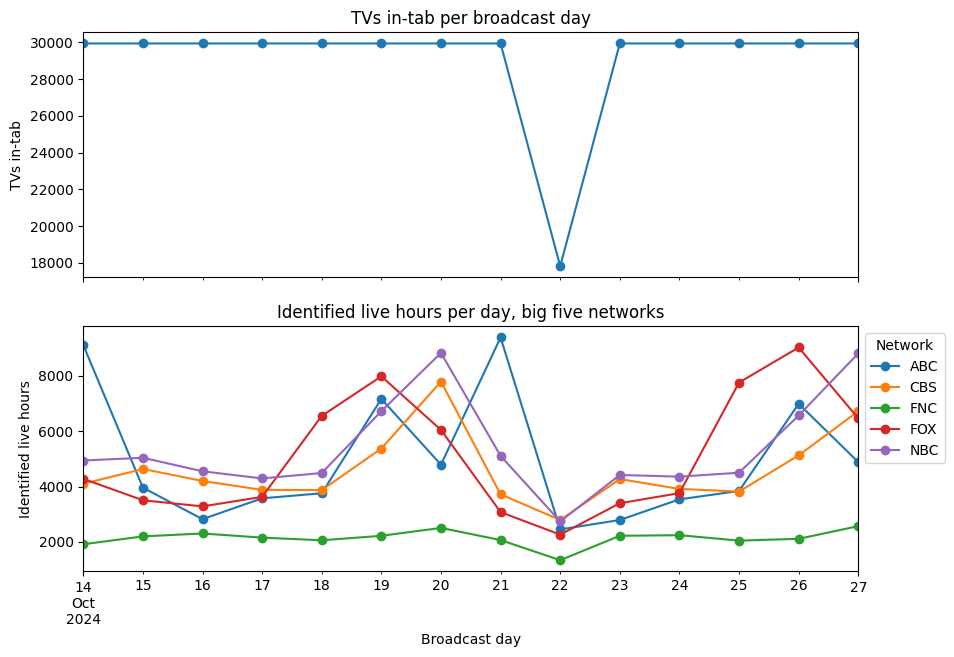

In [34]:
big5=["CBS", "NBC", "ABC", "FOX", "FNC"]
daily_tvs=tv_days.groupby("bday").size()
daily_hours=live[live["network_code"].isin(big5)].pivot_table(index="bday", columns="network_code", values="hours", aggfunc="sum")

fig, (ax1, ax2)=plt.subplots(2, 1, figsize=(10, 7), sharex=True)
daily_tvs.plot(ax=ax1, marker="o")
ax1.set_ylabel("TVs in-tab")
ax1.set_title("TVs in-tab per broadcast day")
daily_hours.plot(ax=ax2, marker="o")
ax2.set_ylabel("Identified live hours")
ax2.set_xlabel("Broadcast day")
ax2.set_title("Identified live hours per day, big five networks")
ax2.legend(title="Network", loc="upper left", bbox_to_anchor=(1, 1))

plt.show()

## Task 4.2 — Spike and broken day

In [35]:
spike_day, spike_net=daily_hours.stack().idxmax()
broken =daily_tvs.idxmin()
hours_per_tv = acr_ok.groupby("bday")["hours"].sum()/ daily_tvs

print("Biggest spike (date, network):", spike_day.strftime("%Y-%m-%d"), spike_net)
on_day = programs[(programs["network_code"] == spike_net) & (pd.to_datetime(programs["broadcast_date"])== spike_day)]
print(on_day[on_day["start_ts"].dt.hour >= 20][["start_ts", "end_ts", "program_name", "episode_name"]].to_string(index=False))
print("Broken day (date):", broken.strftime("%Y-%m-%d"))
print("TVs in-tab that day / on other days:", daily_tvs[broken], "/", int(daily_tvs.drop(broken).median()))
print("Hours per in-tab TV that day / on other days:", f"{hours_per_tv[broken]:.2f}", "/", f"{hours_per_tv.drop(broken).median():.2f}")

Biggest spike (date, network): 2024-10-21 ABC
           start_ts              end_ts                   program_name           episode_name
2024-10-21 20:00:00 2024-10-21 20:15:00  Who Wants to Be a Millionaire                   None
2024-10-21 20:15:00 2024-10-21 23:25:00                   NFL Football NFL Football: BAL @ TB
2024-10-21 23:25:00 2024-10-22 00:35:00 Local / Syndicated Programming                   None
Broken day (date): 2024-10-22
TVs in-tab that day / on other days: 17818 / 29940
Hours per in-tab TV that day / on other days: 4.45 / 4.46


**Answer:** The biggest spike is ABC on 2024-10-21: that Monday evening ABC carried Monday Night Football (Baltimore at Tampa Bay, 20:15–23:25) and a live NFL game draws far more viewers than a normal evening. On 2024-10-22 the data, not the audience, changed: only 17,818 TVs were in-tab instead of 29,940, while each in-tab TV watched as much as on other days (4.45 vs 4.46 hours). So about 40% of the TVs simply did not report that day, a gap in the feed and the hours of all five networks fell at once on the plot. If nobody noticed, the day's totals would look like a sudden 40% drop in viewing and a rating divided by all 29,940 TVs instead of the 17,818 in-tab ones would also be about 40% too low. I would flag the day, not drop it: a rating divided by the TVs in-tab that day is still usable, just from a smaller sample, but the day's raw totals must not be compared with other days unless they are first divided by the TVs in-tab.

## Task 5.1 — Sampling error vs bias

In [36]:
pick=["NFL Football", "Hannity", "Unsellable Houses"]
panel_n=hh_days.groupby("broadcast_date").size()
r=ratings.set_index("Telecast").loc[pick]
day=tel.set_index("program_name").loc[pick, "broadcast_date"].map(pd.Timestamp)
p =r["Reference HH rating"] / 100

se =pd.DataFrame({"SE footprint": (p * (1 - p) / day.map(in_tab)) ** 0.5* 100,
                   "SE panel": (p * (1 - p) / day.map(panel_n)) ** 0.5 *100,
                   "TVs' rating - reference": r["TVs' HH rating"] - r["Reference HH rating"]})
se["Panel SE / footprint SE"] = se["SE panel"] / se["SE footprint"]
print(se.round(2).to_string())

                   SE footprint  SE panel  TVs' rating - reference  Panel SE / footprint SE
Telecast                                                                                   
NFL Football               0.27      0.75                   -11.89                     2.77
Hannity                    0.09      0.24                    -1.48                     2.78
Unsellable Houses          0.11      0.30                    -1.59                     2.78


**Answer:** With about 30,000 TVs instead of the panel's roughly 4,000 homes,, the footprint's sampling error is about 2.8 times smaller (for Sunday Night Football 0.27 rating points instead of 0.75). But the gap between the TVs' rating and the reference is far bigger: −11.89 points for Sunday Night Football, −1.48 for Hannity and −1.59 for Unsellable Houses, which is many times the footprint's standard error and even larger than the panel's. So the bias is the bigger error and more data does not shrink it: more TVs only make the sampling error smaller (it falls with the square root of n), while the gap comes from who is in the footprint and from seeing only one TV per home and adding more of the same opted-in TVs repeats the same skew.

## Task 5.2 — Answer to the planner
**Answer:** From this feed alone I can tell you that 21.2% of the opted-in smart TVs that were on that day watched Sunday Night Football, but this is not a US household rating and it is far below the currency rating of 33.1, so please quote the currency number in tomorrow's presentation, not the feed's. The feed sees one TV per home and no people, so it misses viewing on the other sets in the home, cannot say who was watching and cannot tell us anything about adults 25–54. It also cannot see what is played through apps, games or streaming devices (40% of TV-on time is unknown), or the homes that did not opt in or could not be matched to household data (about a third of the TVs). Its homes are richer and, judging by the ratings, younger than the US, and that bias is many times bigger than its small sampling error, so more TVs would not fix it. Before we use it for planning, we need the feed weighted to the US, a correction for the other TV sets in the home, a way to turn TV homes into people, such as viewers per viewing household from the panel and a check against the currency on many telecasts, with broken days like October 22 flagged first.

## Bonus

In [37]:
snf=tel.set_index("program_name").loc["NFL Football"]
s=viewings[(viewings["network_code"] == snf["network_code"]) & (viewings["start_ts"] < snf["end_ts"]) & (viewings["end_ts"] > snf["start_ts"])]
overlap =(s["end_ts"].clip(upper=snf["end_ts"]) - s["start_ts"].clip(lower=snf["start_ts"])).dt.total_seconds() / 60
mins =overlap.groupby(s["respondent_id"]).sum()
watched =mins[mins >= 1].index

age =viewer_attributes[viewer_attributes["attr_id"] == 300].set_index("respondent_id")["value"]
day_w =dw[dw["broadcast_date"] == pd.Timestamp(snf["broadcast_date"])].copy()
day_w["age"]= day_w["respondent_id"].map(age)
hh= day_w[day_w["resp_type"] == "H"]
a2554= day_w[day_w["resp_type"].isin(["R", "L"]) & day_w["age"].between(25, 54)]
vpvh= a2554[a2554["respondent_id"].isin(watched)]["weight"].sum() / hh[hh["respondent_id"].isin(watched)]["weight"].sum()
tv_rating= ratings.set_index("Telecast").loc["NFL Football", "TVs' HH rating"]
a_rating= tv_rating * vpvh * hh["weight"].sum() / a2554["weight"].sum()

print("VPVH A25-54:", round(vpvh, 3))
print("A25-54 rating (persons):", round(a_rating, 1))

VPVH A25-54: 0.513
A25-54 rating (persons): 11.1


**Answer:** In the panel, every US household that watched Sunday Night Football had on average 0.513 viewers aged 25–54, so the TVs' household rating of 21.2 turns into an A25–54 rating of about 11.1. This assumes that a footprint home that watches the game has the same number of 25–54 viewers as an average US viewing home in the panel, even though the footprint homes are richer and younger, so they may have a different mix of people. It also assumes that the TVs' household rating itself is right, while Task 5.1 showed that it is about 12 points too low, so this A25–54 estimate inherits the same bias and is probably too low as well.